In [22]:
import os
import torch
import numpy as np
import pandas as pd
import scanpy as sc

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from tqdm import tqdm

from SpaBatch.adj import main, combine_graph_dict
from SpaBatch.train import train_model
from SpaBatch.utils import mclust_R, fix_seed
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'

In [23]:
from sklearn.metrics import adjusted_rand_score as ari_score
from sklearn.metrics import normalized_mutual_info_score as nmi_score
from sklearn.metrics import adjusted_mutual_info_score as ami_score
from sklearn.metrics import homogeneity_score as hom_score
from sklearn.metrics import completeness_score as com_score
from sklearn.metrics import v_measure_score as v_score
from SpaBatch.utils import compute_PAS, compute_CHAOS
from sklearn.decomposition import PCA

In [24]:
fix_seed(1)

In [25]:
data_root = Path(r'C:\Code\Data\DLPFC')
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
proj_list = [
    '151669','151670','151671','151672'
]

In [26]:
for proj_name in tqdm(proj_list):
    adata_tmp = sc.read_visium(data_root / proj_name, count_file="filtered_feature_bc_matrix.h5")
    adata_tmp.var_names_make_unique()

    adata_tmp.obs['batch_name'] = proj_name
    graph_dict_tmp = main(adata_tmp, adj_cons_by='coordinate', distType='KNN', k_cutoff=8, rad_cutoff=250)
    
    ##### Load layer_guess label, if have
    df_label = pd.read_csv(data_root / proj_name / f'{proj_name}_truth.txt', sep='\t', header=None, index_col=0)
    df_label.columns = ['layer_guess']
    adata_tmp.obs['layer_guess'] = df_label['layer_guess']
    #adata_tmp= adata_tmp[~pd.isnull(adata_tmp.obs['layer_guess'])]
    
    if proj_name == proj_list[0]:
        adata = adata_tmp
        graph_dict = graph_dict_tmp
        name = proj_name
        adata.obs['proj_name'] = proj_name
    else:
        var_names = adata.var_names.intersection(adata_tmp.var_names)
        adata = adata[:, var_names]
        adata_tmp = adata_tmp[:, var_names]
        adata_tmp.obs['proj_name'] = proj_name
    
        adata = adata.concatenate(adata_tmp)
        graph_dict = combine_graph_dict(graph_dict, graph_dict_tmp)
        name = name + '_' + proj_name

  0%|          | 0/4 [00:00<?, ?it/s]

------Calculating spatial graph...


 25%|██▌       | 1/4 [00:00<00:02,  1.25it/s]

The graph contains 29288 edges, 3661 cells.
8.0000 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 27984 edges, 3498 cells.
8.0000 neighbors per cell on average.


 50%|█████     | 2/4 [00:02<00:02,  1.06s/it]

------Calculating spatial graph...
The graph contains 32880 edges, 4110 cells.
8.0000 neighbors per cell on average.


 75%|███████▌  | 3/4 [00:03<00:01,  1.29s/it]

------Calculating spatial graph...
The graph contains 32120 edges, 4015 cells.
8.0000 neighbors per cell on average.


100%|██████████| 4/4 [00:05<00:00,  1.27s/it]


In [27]:
adata.layers['count'] = adata.X.toarray()
sc.pp.filter_genes(adata, min_cells=50)
sc.pp.filter_genes(adata, min_counts=10)
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)
adata = adata[:, adata.var['highly_variable'] == True]
sc.pp.scale(adata)

from sklearn.decomposition import PCA  # sklearn PCA is used because PCA in scanpy is not stable. 
adata_X = PCA(n_components=200, random_state=42).fit_transform(adata.X)
adata.obsm['X_pca'] = adata_X

In [28]:
SpaBatch_net = train_model(adata, graph_dict, pre_epochs=500 ,epochs=1000, mask_rate=0.2)
using_dec = True
if using_dec:
    SpaBatch_net.train_with_dec(num_aggre=1)
else:
    SpaBatch_net.train_without_dec()

Epoch 499 total loss=19.680: 100%|██████████ [ time left: 00:00 ]           
Epoch 999 total loss=7.870 recon loss=7.124 kl loss=0.047 tri loss=0.275 : |           [ time left: 00:00 ]      


In [29]:
SpaBatch_feat, _ = SpaBatch_net.process()
adata.obsm['SpaBatch'] = SpaBatch_feat

In [30]:
mclust_R(adata, num_cluster=5, used_obsm='SpaBatch')

fitting ...
  |======================================================================| 100%


AnnData object with n_obs × n_vars = 15284 × 2000
    obs: 'in_tissue', 'array_row', 'array_col', 'batch_name', 'layer_guess', 'proj_name', 'batch', 'mclust'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg'
    obsm: 'spatial', 'X_pca', 'Tri_SpaBatch', 'SpaBatch'
    layers: 'count'

In [31]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
ARI = ari_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total ARI:{ARI}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = ari_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI:{ARI}")

total ARI:0.5324762920453561
151669 ARI:0.5525231423674315
151670 ARI:0.5679392438980724
151671 ARI:0.5547242911759798
151672 ARI:0.5747949386607075


In [32]:
# sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
# NMI = nmi_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
# print(f"total NMI:{NMI}")
# for name in proj_list:
#     sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
#     NMI = nmi_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
#     print(f"{name} NMI:{NMI}")

In [33]:
# sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
# HOM = hom_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
# print(f"total HOM:{HOM}")
# for name in proj_list:
#     sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
#     HOM = hom_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
#     print(f"{name} HOM:{HOM}")

In [34]:
# sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
# COM = com_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
# print(f"total COM:{COM}")
# for name in proj_list:
#     sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
#     COM = com_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
#     print(f"{name} COM:{COM}")

In [35]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
NMI = nmi_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total NMI:{NMI}")
AMI = ami_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total AMI:{AMI}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    NMI = nmi_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    AMI = ami_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    ACC = 1/2 * (NMI + AMI)
    print(f"{name} ACC:{ACC}")

total NMI:0.6137509195682911
total AMI:0.6136070107559044
151669 ACC:0.6146538290157622
151670 ACC:0.6048529227982075
151671 ACC:0.6603076475165212
151672 ACC:0.6784294842160035


In [36]:
# sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
# CHAOS = compute_CHAOS(sub_adata, f'mclust')
# print(f"total CHAOS:{CHAOS}")
# for name in proj_list:
#     sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
#     CHAOS = compute_CHAOS(sub_adata_tmp, f'mclust')
#     print(f"{CHAOS}")

In [37]:
# sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
# PAS = compute_PAS(sub_adata, f'mclust')
# print(f"total PAS:{PAS}")
# for name in proj_list:
#     sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
#     PAS = compute_PAS(sub_adata_tmp, f'mclust')
#     print(f"{PAS}")

In [38]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
HOM = hom_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total HOM:{HOM}")
COM = com_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total COM:{COM}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    HOM = hom_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    COM = com_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    V =  2 * ((HOM * COM) / (HOM + COM))
    print(f"{name} V:{V}")

total HOM:0.6554257014876766
total COM:0.5770590274599693
151669 V:0.6149742347851176
151670 V:0.605213549369613
151671 V:0.6605335808825022
151672 V:0.6786507140506834


2.9884102807832122
1.0857041833718468


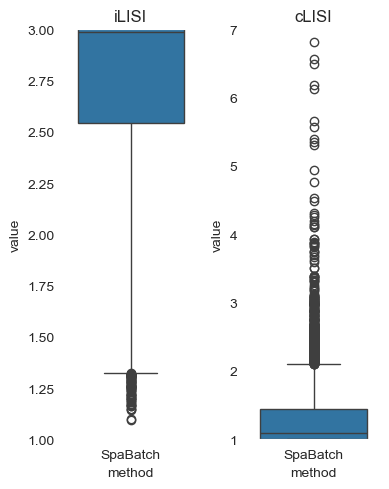

In [39]:
import harmonypy as hm

iLISI = hm.compute_lisi(adata.obsm['SpaBatch'], adata.obs[['batch_name']], label_colnames=['batch_name'])[:, 0]
cLISI = hm.compute_lisi(adata.obsm['SpaBatch'], adata.obs[['layer_guess']], label_colnames=['layer_guess'])[:, 0]
df_iLISI = pd.DataFrame({
    'method': 'SpaBatch',
    'value': iLISI,
    'type': ['ILISI'] * len(iLISI)
})

df_cLISI = pd.DataFrame({
    'method': 'SpaBatch',
    'value': cLISI,
    'type': ['CLISI'] * len(cLISI)
})

fig, axes = plt.subplots(1, 2, figsize=(4, 5))
sns.boxplot(data=df_iLISI, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_cLISI, x='method', y='value', ax=axes[1])
axes[0].set_ylim(1, 3)
axes[1].set_ylim(1, 7)
axes[0].set_title('iLISI')
axes[1].set_title('cLISI')

plt.tight_layout()
print(np.median(iLISI))
print(np.median(cLISI))

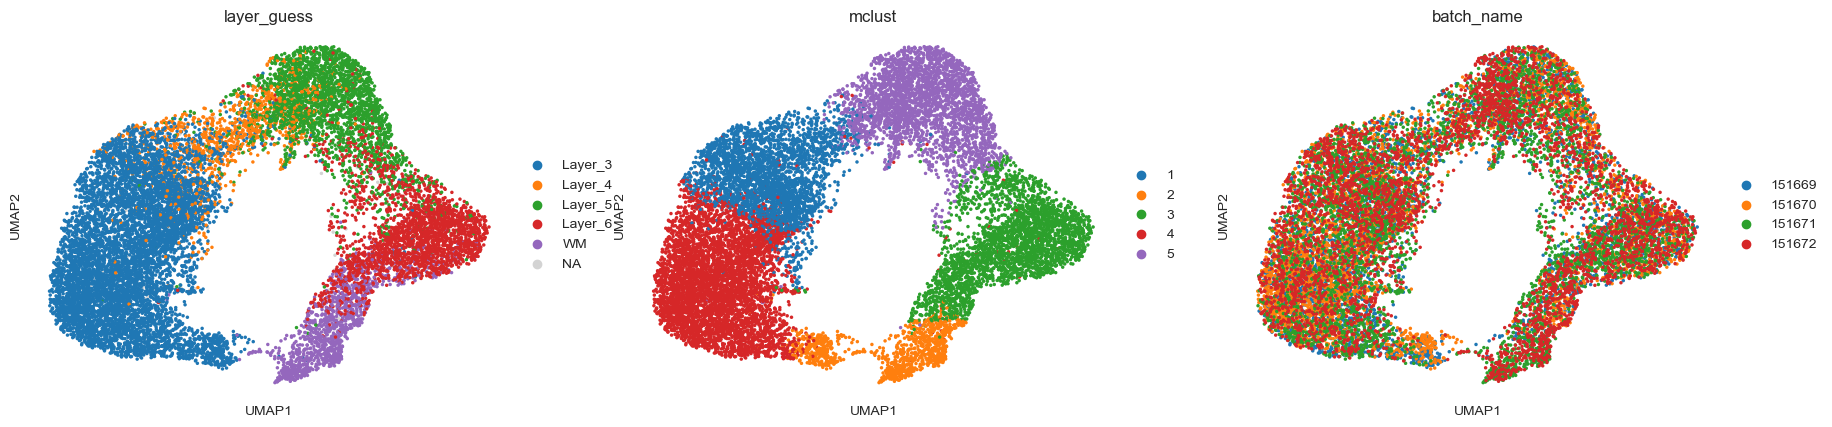

In [40]:
plt.rcParams['axes.facecolor'] = 'white'  # 设置子图的背景颜色
plt.rcParams['figure.facecolor'] = 'white'  # 设置整张图的背景颜色
# plt.rcParams['axes.facecolor'] = 'lightgray'  # 设置子图的背景颜色
# plt.rcParams['figure.facecolor'] = 'lightgray'  # 设置整张图的背景颜色

# %%
sc.pp.neighbors(adata, use_rep='SpaBatch', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['layer_guess', 'mclust', 'batch_name'], show=True, size=25, save=False)

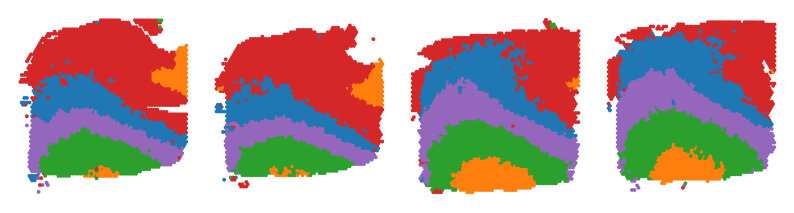

In [41]:
Batch_list = []
for section_id in proj_list:
    Batch_list.append(adata[adata.obs['batch_name'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
# for bb in range(len(proj_list)):
#     ARI_list.append(round(ari_score(Batch_list[bb].obs['layer_guess'], Batch_list[bb].obs['mclust']), 3))
fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(proj_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                         legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                         spot_size=spot_size)
    # _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [42]:
file_name = 'spabatch_Donor2.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)